# Cross-Prompt Feature Validation & Cut Point Derivation

Statistical evidence that extracted features work **consistently across prompts** for conventions scoring.

**Approach:** per-prompt analysis first, then cross-prompt consistency ranking, then quartile-based cut points for the client deliverable.

**Tests:**
- **Spearman rank correlation** — monotonic association between each feature and `conventions_score_norm`
- **Mann-Whitney U** — distributional separation between low/high scoring essays (median split)

Both tests run per-prompt and pooled, with Benjamini-Hochberg FDR correction.

## 1. Setup & Data Loading

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler

# Paths
CACHE_DIR = Path("../cache")
RESULTS_DIR = CACHE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Plot defaults
sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"

In [2]:
# Load data
df = pd.read_parquet(CACHE_DIR / "feature_matrix.parquet")
print(f"Shape: {df.shape}")
print(f"Prompts: {sorted(df['prompt_id'].unique())}")
print(f"Score range: {df['conventions_score_norm'].min():.3f} – {df['conventions_score_norm'].max():.3f}")
print(f"Score median: {df['conventions_score_norm'].median():.3f}")
df.head(3)

Shape: (5875, 84)
Prompts: [1, 2, 7, 8]
Score range: 0.000 – 1.000
Score median: 0.600


,essay_id,prompt_id,conventions_score,conventions_score_norm,word_count,dep_mdd_mean,dep_mdd_stdev,dep_mdd_max,dep_mdd_advcl,dep_mdd_relcl,...,agg_total_words,agg_words_per_sentence,agg_errors_per_sentence_mean,agg_errors_per_sentence_max,agg_errors_per_sentence_stdev,agg_error_free_sentence_ratio,agg_worst_window_3_errors,agg_worst_window_3_mean,agg_mdd_consistency,agg_error_concentration
0,1,1,3.0,0.4,351,2.912703,0.754850,4.205882,9.785714,2.25,...,351.0,21.937500,1.062500,3.0,1.062623,0.375000,7.0,3.285714,0.754850,0.262868
1,2,1,4.0,0.6,423,2.689029,0.598957,3.978723,7.400000,2.75,...,423.0,21.150000,1.350000,6.0,1.348488,0.200000,10.0,4.111111,0.598957,0.223148
2,3,1,4.0,0.6,283,2.390058,0.742676,3.222222,3.250000,2.00,...,283.0,16.647059,0.823529,5.0,1.509772,0.647059,10.0,2.800000,0.742676,0.386555


Shape: (5875, 84)
Prompts: [1, 2, 7, 8]
Score range: 0.000 – 1.000
Score median: 0.600


,essay_id,prompt_id,conventions_score,conventions_score_norm,word_count,dep_mdd_mean,dep_mdd_stdev,dep_mdd_max,dep_mdd_advcl,dep_mdd_relcl,...,agg_total_words,agg_words_per_sentence,agg_errors_per_sentence_mean,agg_errors_per_sentence_max,agg_errors_per_sentence_stdev,agg_error_free_sentence_ratio,agg_worst_window_3_errors,agg_worst_window_3_mean,agg_mdd_consistency,agg_error_concentration
0,1,1,3.0,0.4,351,2.912703,0.754850,4.205882,9.785714,2.25,...,351.0,21.937500,1.062500,3.0,1.062623,0.375000,7.0,3.285714,0.754850,0.262868
1,2,1,4.0,0.6,423,2.689029,0.598957,3.978723,7.400000,2.75,...,423.0,21.150000,1.350000,6.0,1.348488,0.200000,10.0,4.111111,0.598957,0.223148
2,3,1,4.0,0.6,283,2.390058,0.742676,3.222222,3.250000,2.00,...,283.0,16.647059,0.823529,5.0,1.509772,0.647059,10.0,2.800000,0.742676,0.386555


Shape: (5875, 84)
Prompts: [1, 2, 7, 8]
Score range: 0.000 – 1.000
Score median: 0.600


,essay_id,prompt_id,conventions_score,conventions_score_norm,word_count,dep_mdd_mean,dep_mdd_stdev,dep_mdd_max,dep_mdd_advcl,dep_mdd_relcl,...,agg_total_words,agg_words_per_sentence,agg_errors_per_sentence_mean,agg_errors_per_sentence_max,agg_errors_per_sentence_stdev,agg_error_free_sentence_ratio,agg_worst_window_3_errors,agg_worst_window_3_mean,agg_mdd_consistency,agg_error_concentration
0,1,1,3.0,0.4,351,2.912703,0.754850,4.205882,9.785714,2.25,...,351.0,21.937500,1.062500,3.0,1.062623,0.375000,7.0,3.285714,0.754850,0.262868
1,2,1,4.0,0.6,423,2.689029,0.598957,3.978723,7.400000,2.75,...,423.0,21.150000,1.350000,6.0,1.348488,0.200000,10.0,4.111111,0.598957,0.223148
2,3,1,4.0,0.6,283,2.390058,0.742676,3.222222,3.250000,2.00,...,283.0,16.647059,0.823529,5.0,1.509772,0.647059,10.0,2.800000,0.742676,0.386555


Shape: (5875, 84)
Prompts: [1, 2, 7, 8]
Score range: 0.000 – 1.000
Score median: 0.600


,essay_id,prompt_id,conventions_score,conventions_score_norm,word_count,dep_mdd_mean,dep_mdd_stdev,dep_mdd_max,dep_mdd_advcl,dep_mdd_relcl,...,agg_total_words,agg_words_per_sentence,agg_errors_per_sentence_mean,agg_errors_per_sentence_max,agg_errors_per_sentence_stdev,agg_error_free_sentence_ratio,agg_worst_window_3_errors,agg_worst_window_3_mean,agg_mdd_consistency,agg_error_concentration
0,1,1,3.0,0.4,351,2.912703,0.754850,4.205882,9.785714,2.25,...,351.0,21.937500,1.062500,3.0,1.062623,0.375000,7.0,3.285714,0.754850,0.262868
1,2,1,4.0,0.6,423,2.689029,0.598957,3.978723,7.400000,2.75,...,423.0,21.150000,1.350000,6.0,1.348488,0.200000,10.0,4.111111,0.598957,0.223148
2,3,1,4.0,0.6,283,2.390058,0.742676,3.222222,3.250000,2.00,...,283.0,16.647059,0.823529,5.0,1.509772,0.647059,10.0,2.800000,0.742676,0.386555


In [3]:
# Identify feature columns vs metadata
METADATA_COLS = ["essay_id", "prompt_id", "conventions_score", "conventions_score_norm", "word_count"]
FEATURE_COLS = [c for c in df.columns if c not in METADATA_COLS]
TARGET = "conventions_score_norm"

# Module prefix mapping
MODULE_MAP = {
    "dep_": "Dependency",
    "syn_": "Syntactic",
    "punct_": "Punctuation",
    "err_": "Error Severity",
    "spell_": "Spelling",
    "agg_": "Aggregation",
}

def get_module(col: str) -> str:
    for prefix, name in MODULE_MAP.items():
        if col.startswith(prefix):
            return name
    return "Unknown"

feature_modules = pd.Series({f: get_module(f) for f in FEATURE_COLS})
print(f"Feature columns: {len(FEATURE_COLS)}")
print(f"\nFeatures per module:")
print(feature_modules.value_counts().sort_index())

Feature columns: 79

Features per module:
Aggregation       11
Dependency        22
Error Severity    19
Punctuation        8
Spelling           8
Syntactic         11
Name: count, dtype: int64


In [4]:
# Scaled features for visualization (rank-based tests are unaffected)
scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[FEATURE_COLS] = scaler.fit_transform(df[FEATURE_COLS].fillna(0))
print("StandardScaler applied for visualization use.")

StandardScaler applied for visualization use.


## 2. Core Analysis Functions

In [5]:
def spearman_analysis(
    data: pd.DataFrame,
    features: list[str],
    target: str = TARGET,
) -> pd.DataFrame:
    """Spearman rho + p-value for each feature vs target."""
    rows = []
    y = data[target].values
    for feat in features:
        x = data[feat].fillna(0).values
        if np.std(x) == 0:
            rows.append({"feature": feat, "spearman_rho": 0.0, "spearman_p": 1.0})
            continue
        rho, p = stats.spearmanr(x, y)
        rows.append({"feature": feat, "spearman_rho": rho, "spearman_p": p})
    return pd.DataFrame(rows)


def mann_whitney_analysis(
    data: pd.DataFrame,
    features: list[str],
    target: str = TARGET,
) -> pd.DataFrame:
    """Mann-Whitney U with median split (excluding ties at median).

    Rank-biserial effect size: r = 1 - 2U/(n1*n2)
    """
    median_val = data[target].median()
    low = data[data[target] < median_val]
    high = data[data[target] > median_val]
    n_excluded = len(data) - len(low) - len(high)

    rows = []
    for feat in features:
        x_low = low[feat].fillna(0).values
        x_high = high[feat].fillna(0).values
        if len(x_low) < 2 or len(x_high) < 2:
            rows.append({
                "feature": feat, "mwu_U": np.nan, "mwu_p": np.nan,
                "rank_biserial_r": np.nan, "n_low": len(x_low),
                "n_high": len(x_high), "n_excluded": n_excluded,
            })
            continue
        if np.std(x_low) == 0 and np.std(x_high) == 0 and x_low[0] == x_high[0]:
            rows.append({
                "feature": feat, "mwu_U": len(x_low) * len(x_high) / 2,
                "mwu_p": 1.0, "rank_biserial_r": 0.0,
                "n_low": len(x_low), "n_high": len(x_high),
                "n_excluded": n_excluded,
            })
            continue
        U, p = stats.mannwhitneyu(x_low, x_high, alternative="two-sided")
        n1, n2 = len(x_low), len(x_high)
        r = 1 - (2 * U) / (n1 * n2)
        rows.append({
            "feature": feat, "mwu_U": U, "mwu_p": p,
            "rank_biserial_r": r, "n_low": n1, "n_high": n2,
            "n_excluded": n_excluded,
        })
    return pd.DataFrame(rows)


def apply_fdr(p_values: np.ndarray, alpha: float = 0.05) -> tuple[np.ndarray, np.ndarray]:
    """Benjamini-Hochberg FDR correction.

    Returns (q_values, significant_mask). NaN p-values get q=NaN, sig=False.
    """
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    if n == 0:
        return np.array([]), np.array([], dtype=bool)

    nan_mask = np.isnan(p)
    p_clean = np.where(nan_mask, 1.0, p)

    order = np.argsort(p_clean)
    ranked = np.empty(n, dtype=float)
    ranked[order] = np.arange(1, n + 1)

    q = p_clean * n / ranked
    rev_order = np.argsort(-ranked)
    q_sorted = q[rev_order]
    q_cummin = np.minimum.accumulate(q_sorted)
    q[rev_order] = q_cummin
    q = np.clip(q, 0, 1)

    q[nan_mask] = np.nan
    sig = np.where(nan_mask, False, q <= alpha)

    return q, sig


def run_full_analysis(
    data: pd.DataFrame,
    features: list[str],
    target: str = TARGET,
    alpha: float = 0.05,
) -> pd.DataFrame:
    """Run Spearman + MWU + FDR, return merged DataFrame sorted by |rho|."""
    sp = spearman_analysis(data, features, target)
    mw = mann_whitney_analysis(data, features, target)
    merged = sp.merge(mw, on="feature")

    sp_q, sp_sig = apply_fdr(merged["spearman_p"].values, alpha)
    merged["spearman_q"] = sp_q
    merged["spearman_sig"] = sp_sig

    mw_q, mw_sig = apply_fdr(merged["mwu_p"].fillna(1).values, alpha)
    merged["mwu_q"] = mw_q
    merged["mwu_sig"] = mw_sig

    merged["abs_rho"] = merged["spearman_rho"].abs()
    merged["abs_r"] = merged["rank_biserial_r"].abs()
    merged["module"] = merged["feature"].map(lambda f: get_module(f))

    return merged.sort_values("abs_rho", ascending=False).reset_index(drop=True)


print("Analysis functions defined.")

Analysis functions defined.


## 3. Per-Prompt Analysis

Run the full statistical analysis independently for each prompt.

In [6]:
prompts = sorted(df["prompt_id"].unique())
prompt_results = {}

for pid in prompts:
    subset = df[df["prompt_id"] == pid]
    result = run_full_analysis(subset, FEATURE_COLS)
    result["prompt_id"] = pid
    prompt_results[pid] = result

    median_val = subset[TARGET].median()
    n_low = (subset[TARGET] < median_val).sum()
    n_high = (subset[TARGET] > median_val).sum()
    n_sp = result["spearman_sig"].sum()
    n_mw = result["mwu_sig"].sum()

    print(f"Prompt {pid}: N={len(subset):,}, median={median_val:.3f}, "
          f"Low={n_low}, High={n_high}, "
          f"Spearman sig={n_sp}/{len(FEATURE_COLS)}, MWU sig={n_mw}/{len(FEATURE_COLS)}")

Prompt 1: N=1,783, median=0.600, Low=710, High=371, Spearman sig=54/79, MWU sig=54/79
Prompt 2: N=1,800, median=0.400, Low=510, High=670, Spearman sig=65/79, MWU sig=62/79
Prompt 7: N=1,569, median=0.667, Low=336, High=707, Spearman sig=56/79, MWU sig=56/79
Prompt 8: N=723, median=0.500, Low=242, High=299, Spearman sig=66/79, MWU sig=65/79


## 4. Cross-Prompt Consistency

Do features behave consistently across prompts?

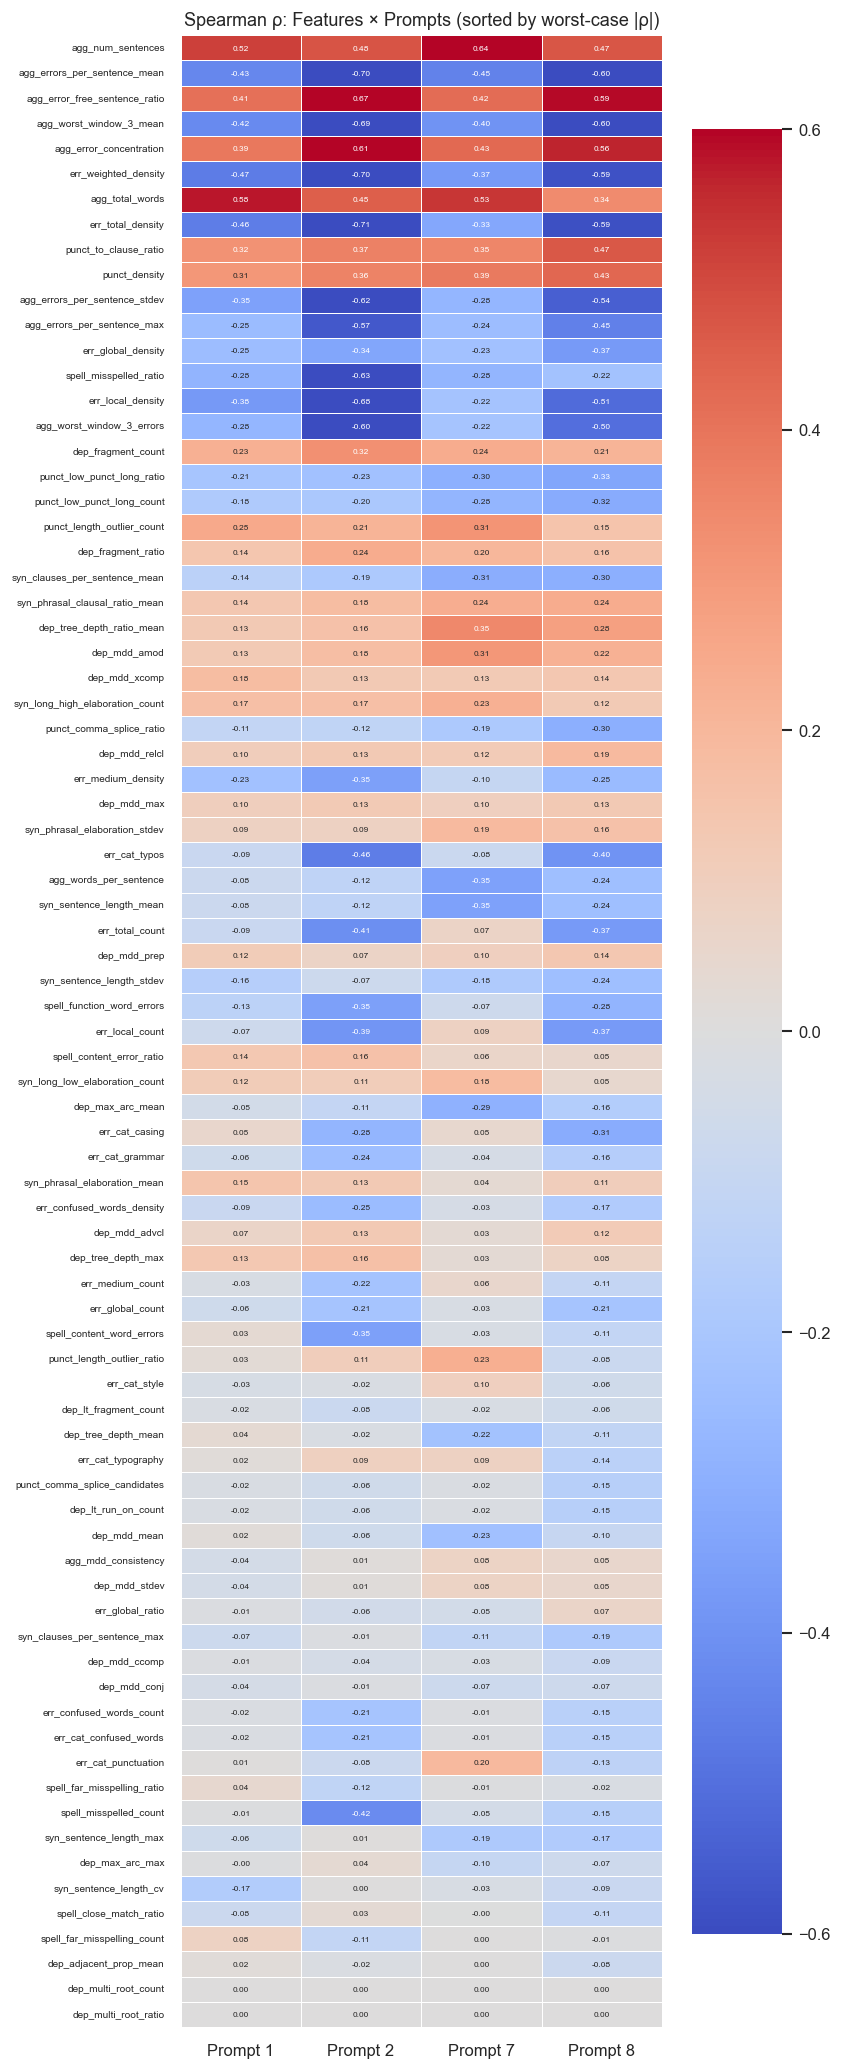

In [7]:
# --- 4a. Spearman rho heatmap (features × prompts) ---
# Build matrix: rows=features, cols=prompts only (no pooled)
# Sort features by min |rho| across prompts (best cross-prompt features on top)
rho_matrix = pd.DataFrame(index=FEATURE_COLS)
for pid in prompts:
    pr = prompt_results[pid].set_index("feature")
    rho_matrix[f"Prompt {pid}"] = pr["spearman_rho"]

# Sort by min absolute rho (worst-case across prompts)
rho_matrix["_min_abs"] = rho_matrix.abs().min(axis=1)
rho_matrix = rho_matrix.sort_values("_min_abs", ascending=False)
rho_matrix = rho_matrix.drop(columns="_min_abs")

fig, ax = plt.subplots(figsize=(7, max(14, len(FEATURE_COLS) * 0.22)))
sns.heatmap(
    rho_matrix, cmap="coolwarm", center=0, vmin=-0.6, vmax=0.6,
    annot=True, fmt=".2f", annot_kws={"fontsize": 5},
    xticklabels=True, yticklabels=True, ax=ax, linewidths=0.3,
)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=6)
ax.set_title("Spearman \u03c1: Features \u00d7 Prompts (sorted by worst-case |\u03c1|)")
plt.tight_layout()
plt.show()

In [8]:
# --- 4b. Cross-prompt consistency metrics ---
ranking_rows = []
for feat in FEATURE_COLS:
    rhos = []
    n_sig = 0
    signs = []
    for pid in prompts:
        row = prompt_results[pid][prompt_results[pid]["feature"] == feat].iloc[0]
        rho_val = row["spearman_rho"]
        rhos.append(rho_val)
        if row["spearman_sig"] or row["mwu_sig"]:
            n_sig += 1
        if rho_val != 0:
            signs.append(np.sign(rho_val))

    abs_rhos = [abs(r) for r in rhos]
    sign_consistent = len(set(signs)) <= 1
    mean_rho = np.mean(rhos)  # signed mean for direction

    ranking_rows.append({
        "feature": feat,
        "module": get_module(feat),
        "mean_rho": mean_rho,
        "mean_abs_rho": np.mean(abs_rhos),
        "min_abs_rho": np.min(abs_rhos),
        "max_abs_rho": np.max(abs_rhos),
        "n_significant": n_sig,
        "n_prompts": len(prompts),
        "sign_consistent": sign_consistent,
        "direction": "higher_is_better" if mean_rho > 0 else "lower_is_better",
    })

cross_ranking = (
    pd.DataFrame(ranking_rows)
    .sort_values("min_abs_rho", ascending=False)
    .reset_index(drop=True)
)

print(f"Features ranked by min |\u03c1| (worst-case across {len(prompts)} prompts):")
print(f"Sign-consistent: {cross_ranking['sign_consistent'].sum()}/{len(FEATURE_COLS)}")
print(f"Significant in all prompts: {(cross_ranking['n_significant'] == len(prompts)).sum()}/{len(FEATURE_COLS)}")
print()
cross_ranking[["feature", "module", "min_abs_rho", "mean_abs_rho", "max_abs_rho",
               "n_significant", "sign_consistent", "direction"]].head(25)

Features ranked by min |ρ| (worst-case across 4 prompts):
Sign-consistent: 58/79
Significant in all prompts: 42/79



,feature,module,min_abs_rho,mean_abs_rho,max_abs_rho,n_significant,sign_consistent,direction
0,agg_num_sentences,Aggregation,0.472529,0.526838,0.638500,4,True,higher_is_better
1,agg_errors_per_sentence_mean,Aggregation,0.432962,0.546504,0.701223,4,True,lower_is_better
2,agg_error_free_sentence_ratio,Aggregation,0.407933,0.522960,0.671498,4,True,higher_is_better
3,agg_worst_window_3_mean,Aggregation,0.395109,0.526619,0.691621,4,True,lower_is_better
4,agg_error_concentration,Aggregation,0.389308,0.498710,0.614182,4,True,higher_is_better
5,err_weighted_density,Error Severity,0.373458,0.532505,0.703774,4,True,lower_is_better
6,agg_total_words,Aggregation,0.337556,0.476138,0.581017,4,True,higher_is_better
7,err_total_density,Error Severity,0.331879,0.523495,0.713957,4,True,lower_is_better
8,punct_to_clause_ratio,Punctuation,0.321852,0.377436,0.465105,4,True,higher_is_better
9,punct_density,Punctuation,0.305895,0.372645,0.431563,4,True,higher_is_better


In [9]:
# --- 4c. Feature categorization ---
n_prompts = len(prompts)
min_prompts = n_prompts - 1  # significant in >= 3/4 prompts

consistent_strong = cross_ranking[
    (cross_ranking["n_significant"] >= min_prompts) & cross_ranking["sign_consistent"]
]
prompt_specific = cross_ranking[~cross_ranking["sign_consistent"]]
dead_features = cross_ranking[cross_ranking["n_significant"] == 0]

print(f"CROSS-PROMPT CONSISTENT (sig in \u2265{min_prompts}/{n_prompts} prompts, sign-consistent): "
      f"{len(consistent_strong)}")
for _, row in consistent_strong.iterrows():
    print(f"  {row['feature']:45s}  min|\u03c1|={row['min_abs_rho']:.3f}  "
          f"sig={row['n_significant']}/{n_prompts}  dir={row['direction']}")

print(f"\nPROMPT-SPECIFIC (sign flips): {len(prompt_specific)}")
for _, row in prompt_specific.iterrows():
    print(f"  {row['feature']:45s}  min|\u03c1|={row['min_abs_rho']:.3f}  module={row['module']}")

print(f"\nDEAD FEATURES (sig in 0 prompts): {len(dead_features)}")
for _, row in dead_features.iterrows():
    print(f"  {row['feature']:45s}  module={row['module']}")

CROSS-PROMPT CONSISTENT (sig in ≥3/4 prompts, sign-consistent): 48
  agg_num_sentences                              min|ρ|=0.473  sig=4/4  dir=higher_is_better
  agg_errors_per_sentence_mean                   min|ρ|=0.433  sig=4/4  dir=lower_is_better
  agg_error_free_sentence_ratio                  min|ρ|=0.408  sig=4/4  dir=higher_is_better
  agg_worst_window_3_mean                        min|ρ|=0.395  sig=4/4  dir=lower_is_better
  agg_error_concentration                        min|ρ|=0.389  sig=4/4  dir=higher_is_better
  err_weighted_density                           min|ρ|=0.373  sig=4/4  dir=lower_is_better
  agg_total_words                                min|ρ|=0.338  sig=4/4  dir=higher_is_better
  err_total_density                              min|ρ|=0.332  sig=4/4  dir=lower_is_better
  punct_to_clause_ratio                          min|ρ|=0.322  sig=4/4  dir=higher_is_better
  punct_density                                  min|ρ|=0.306  sig=4/4  dir=higher_is_better
  agg_e

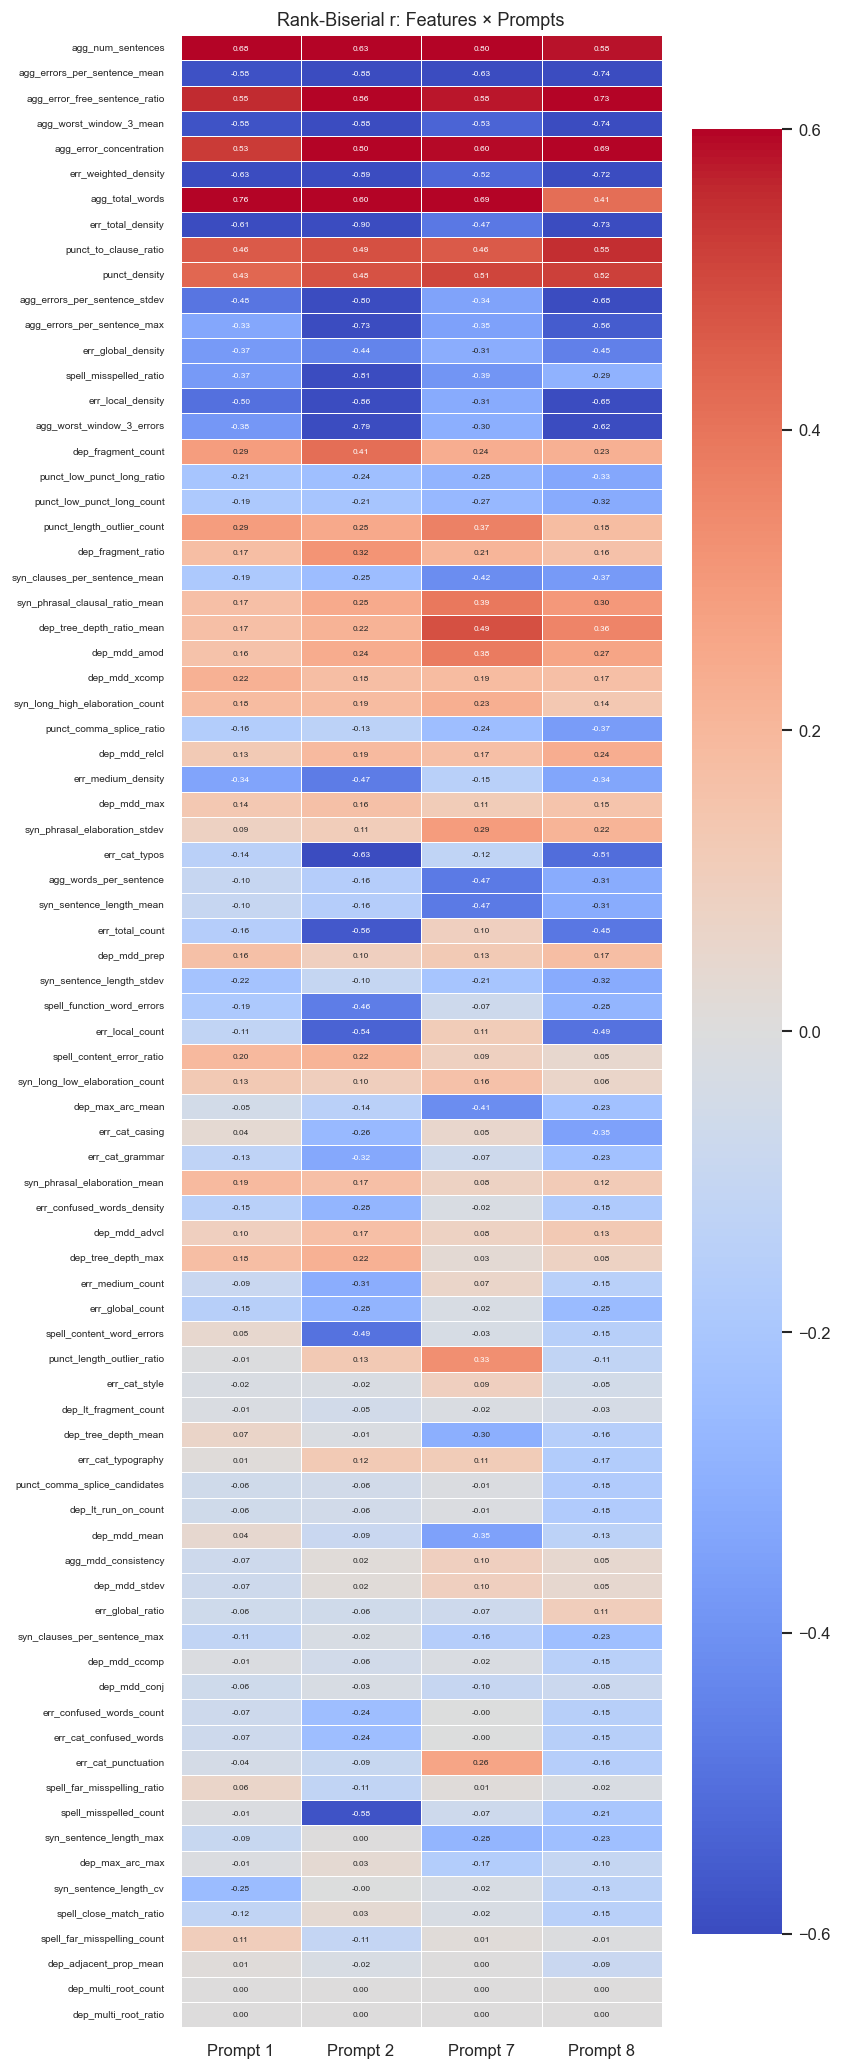

In [10]:
# --- 4d. Rank-biserial r heatmap (features × prompts) ---
r_matrix = pd.DataFrame(index=FEATURE_COLS)
for pid in prompts:
    pr = prompt_results[pid].set_index("feature")
    r_matrix[f"Prompt {pid}"] = pr["rank_biserial_r"]

# Same sort order as rho heatmap
r_matrix = r_matrix.loc[rho_matrix.index]

fig, ax = plt.subplots(figsize=(7, max(14, len(FEATURE_COLS) * 0.22)))
sns.heatmap(
    r_matrix, cmap="coolwarm", center=0, vmin=-0.6, vmax=0.6,
    annot=True, fmt=".2f", annot_kws={"fontsize": 5},
    xticklabels=True, yticklabels=True, ax=ax, linewidths=0.3,
)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=6)
ax.set_title("Rank-Biserial r: Features \u00d7 Prompts")
plt.tight_layout()
plt.show()

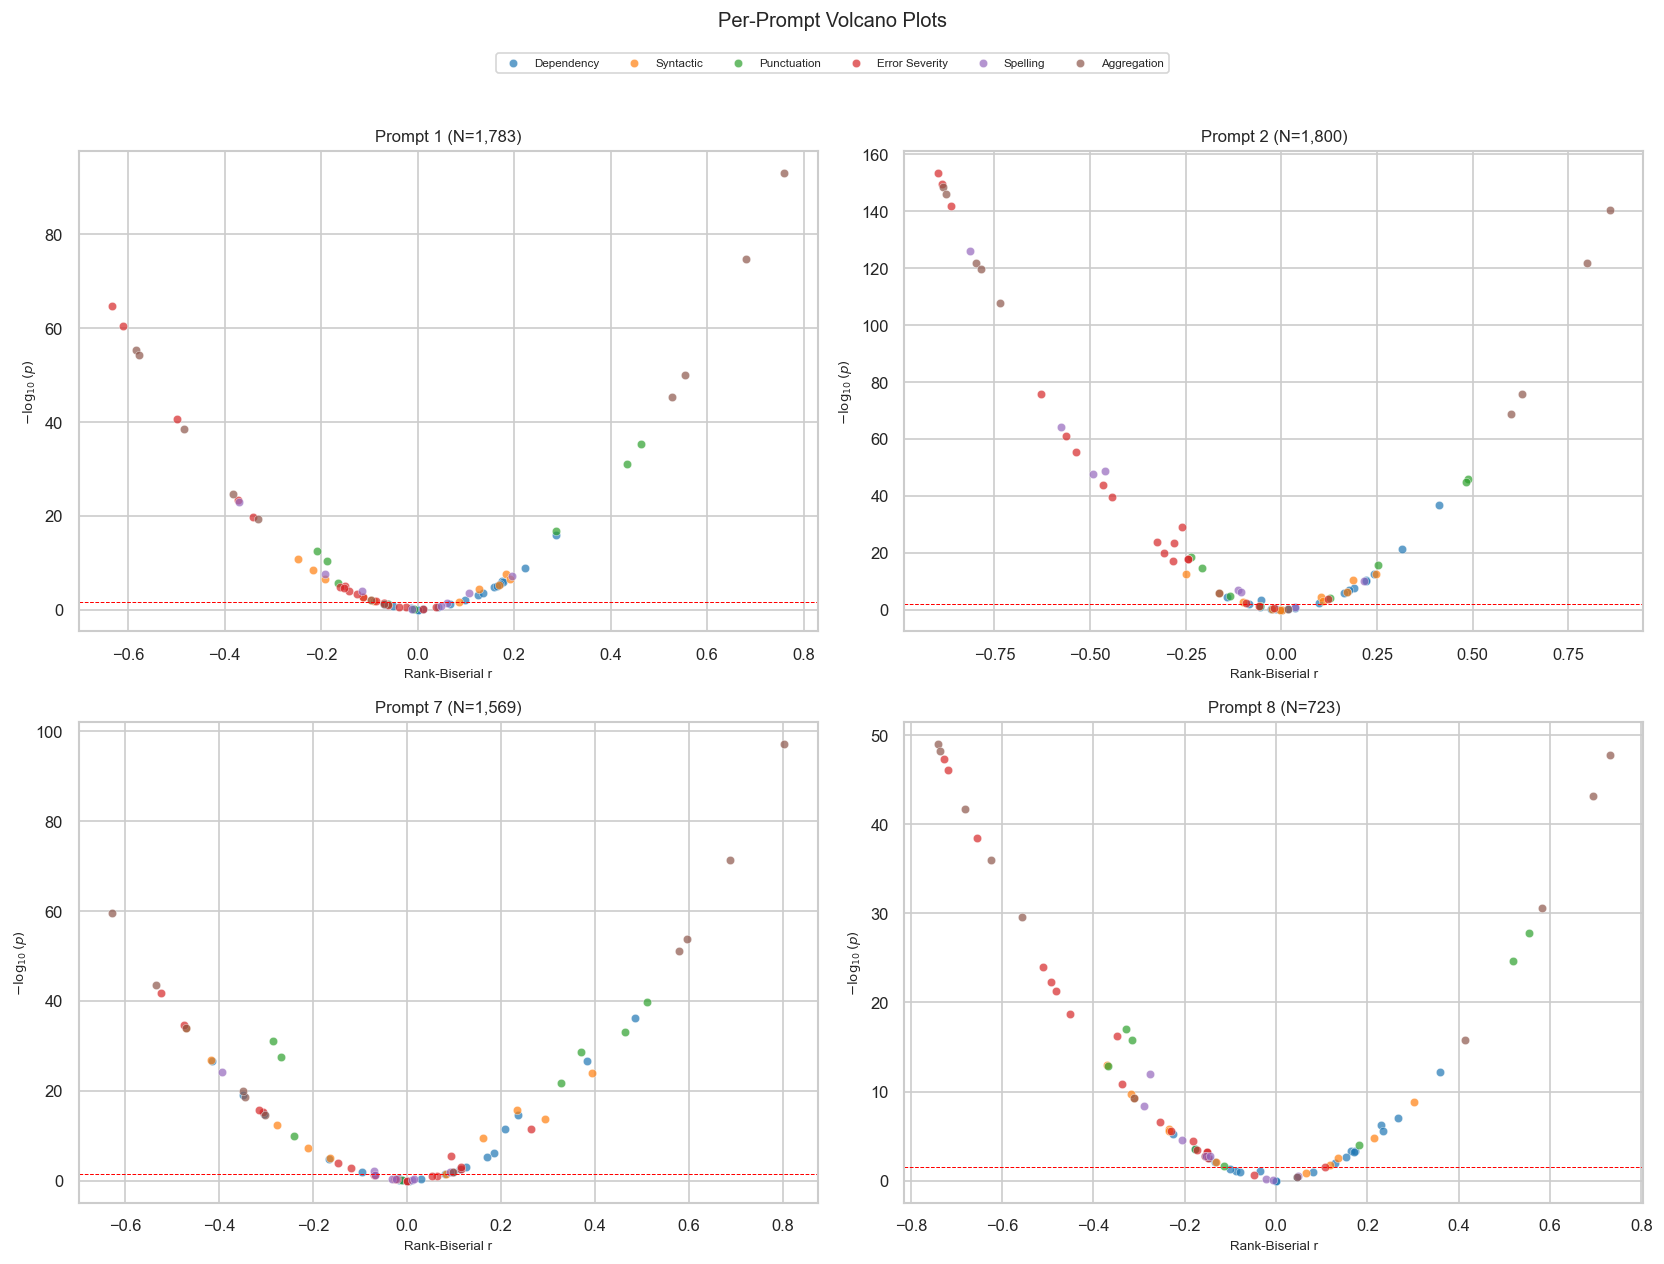

In [11]:
# --- 4e. Per-prompt volcano plots (2×2 grid) ---
module_order = ["Dependency", "Syntactic", "Punctuation", "Error Severity", "Spelling", "Aggregation"]
module_colors = {
    "Dependency": "#1f77b4",
    "Syntactic": "#ff7f0e",
    "Punctuation": "#2ca02c",
    "Error Severity": "#d62728",
    "Spelling": "#9467bd",
    "Aggregation": "#8c564b",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, pid in zip(axes.ravel(), prompts):
    pr = prompt_results[pid]
    for mod in module_order:
        mask = pr["module"] == mod
        subset = pr[mask]
        ax.scatter(
            subset["rank_biserial_r"],
            -np.log10(subset["mwu_p"].clip(lower=1e-300)),
            c=module_colors[mod], label=mod, alpha=0.7, s=25,
            edgecolors="white", linewidth=0.3,
        )
    fdr_thr = pr.loc[pr["mwu_sig"], "mwu_p"].max() if pr["mwu_sig"].any() else 0.05
    ax.axhline(-np.log10(fdr_thr), color="red", linestyle="--", linewidth=0.6)
    ax.set_title(f"Prompt {pid} (N={len(df[df['prompt_id']==pid]):,})", fontsize=10)
    ax.set_xlabel("Rank-Biserial r", fontsize=8)
    ax.set_ylabel(r"$-\log_{10}(p)$", fontsize=8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=6, fontsize=7, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Per-Prompt Volcano Plots", fontsize=12, y=1.05)
plt.tight_layout()
plt.show()

## 5. Inter-Feature Correlation

Spearman correlation between features, grouped by module. Useful for identifying redundant features before cut point derivation.

Cross-prompt consistent features for correlation analysis: 48/79


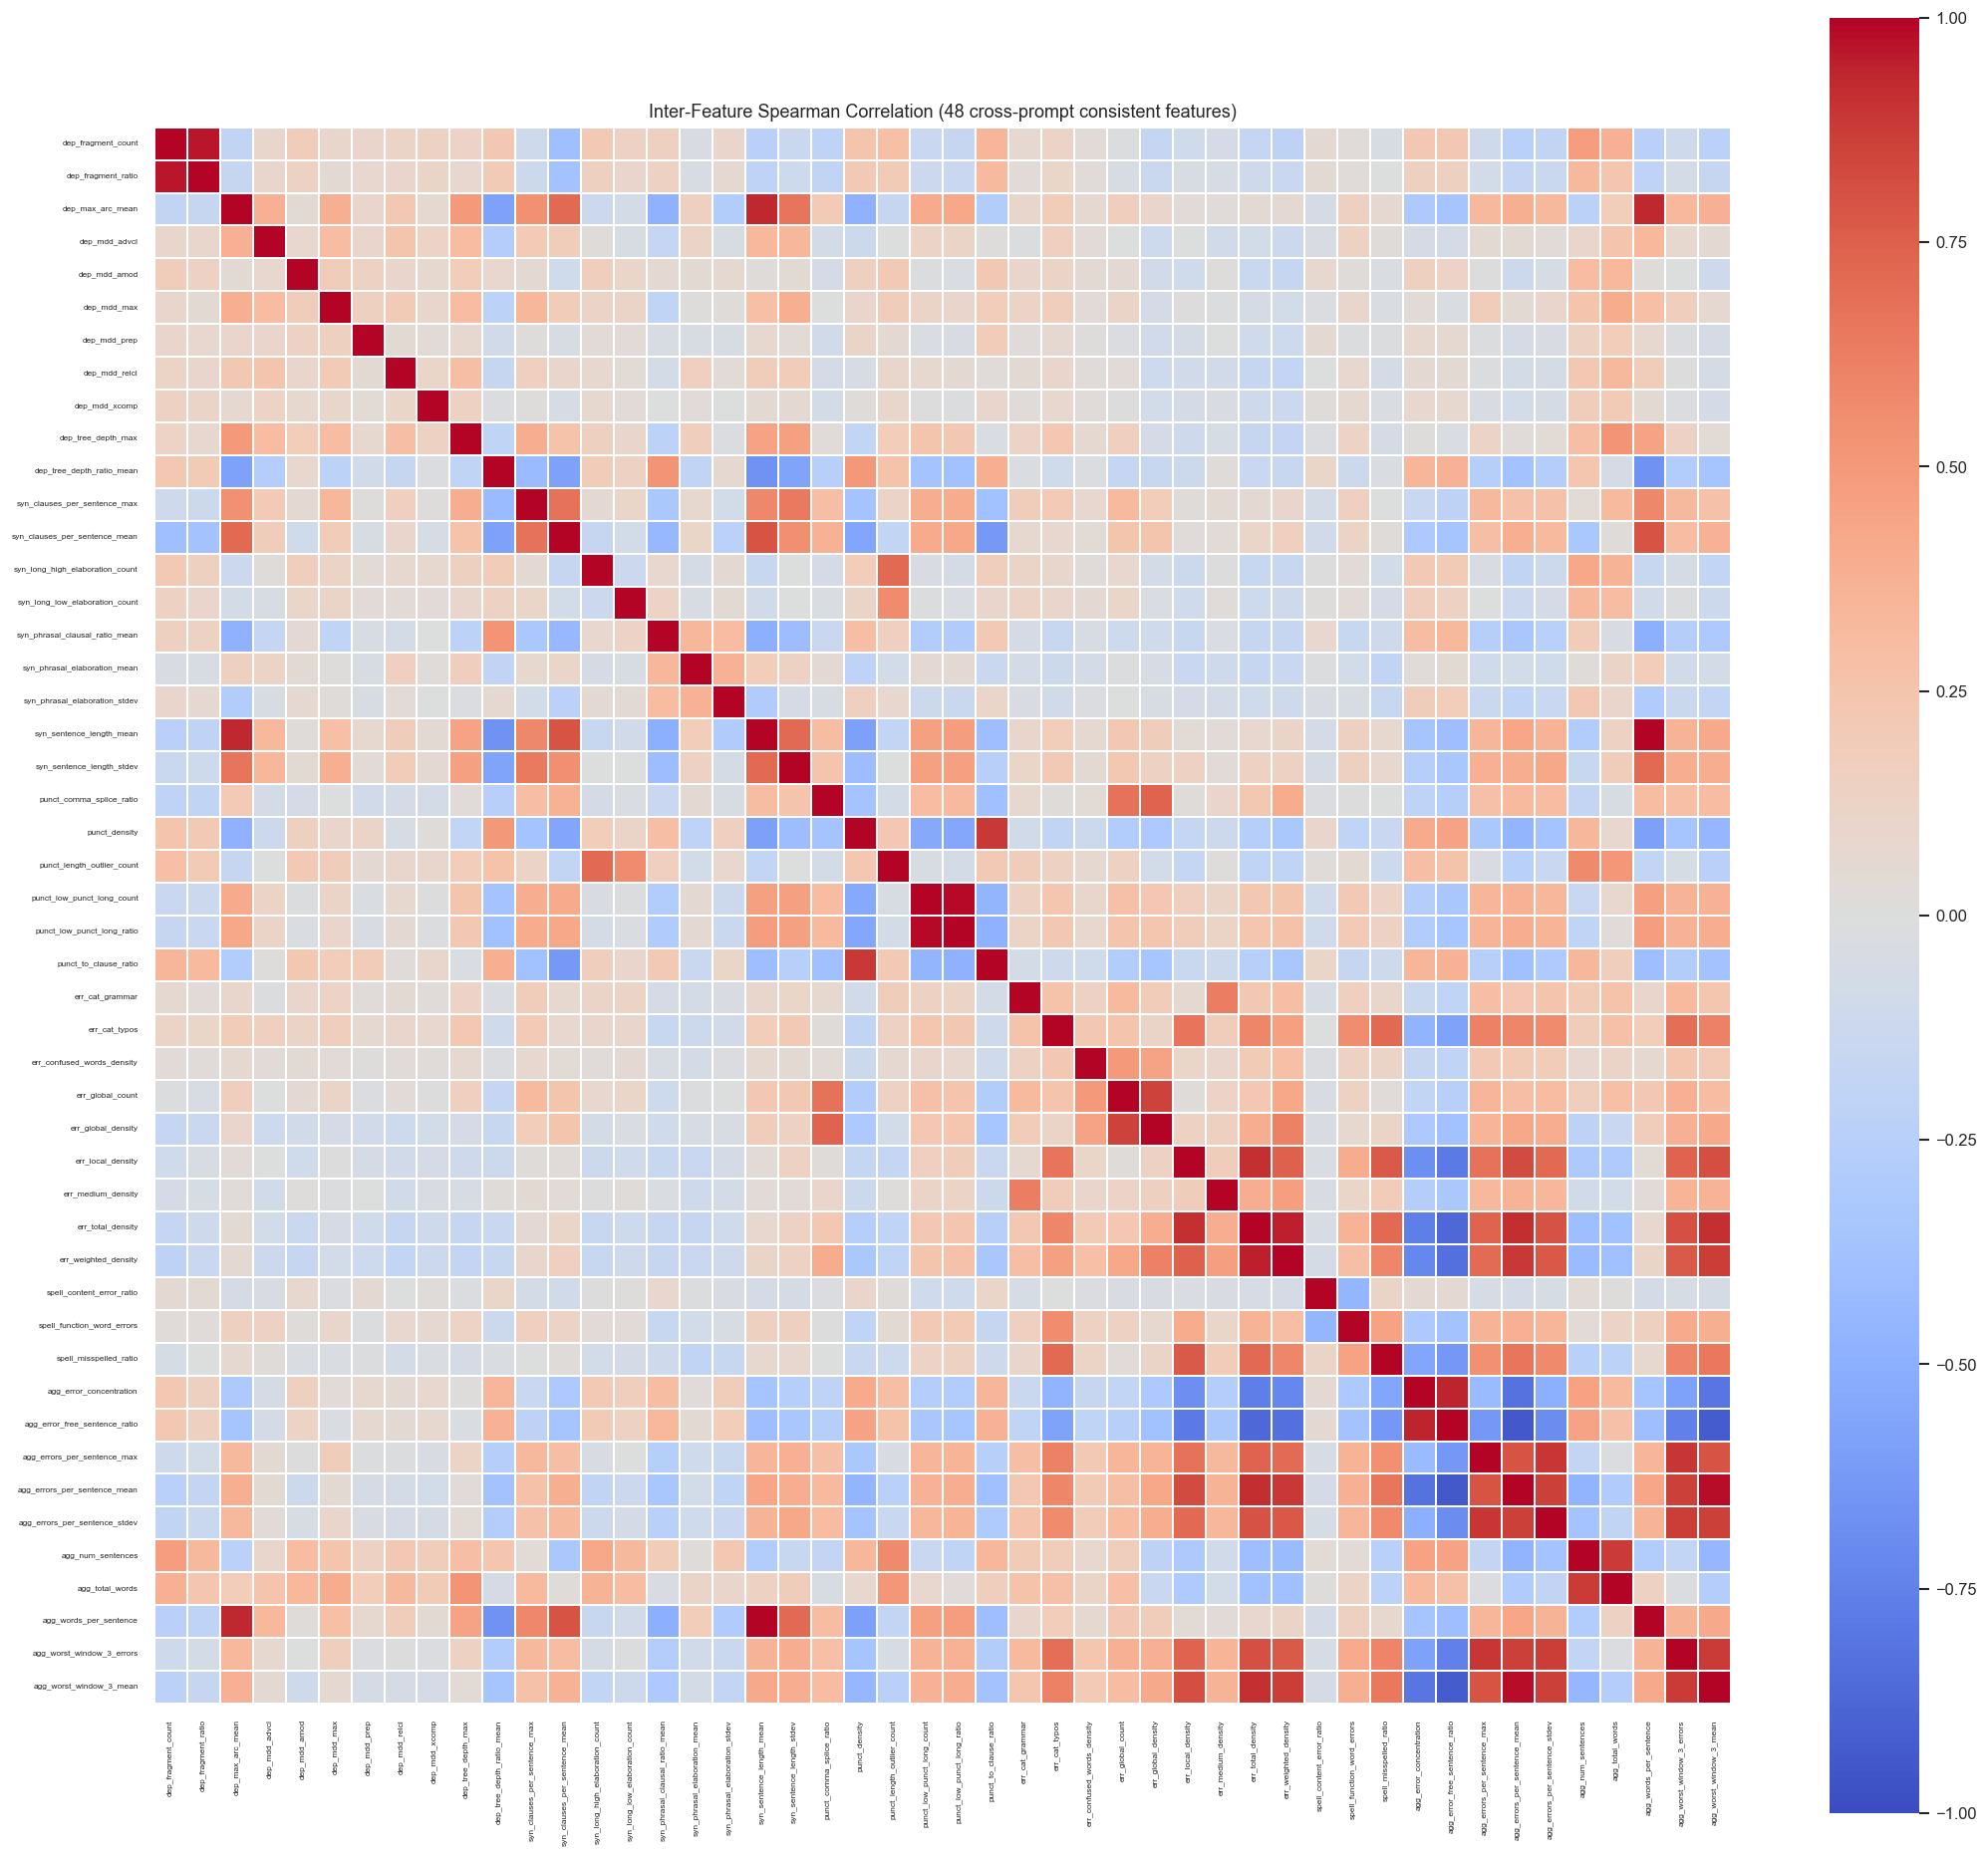

In [12]:
# Filter to cross-prompt consistent features only (not all 78)
n_prompts = len(prompts)
min_prompts_corr = n_prompts - 1  # >= 3/4
consistent_feats = cross_ranking[
    (cross_ranking["n_significant"] >= min_prompts_corr) & cross_ranking["sign_consistent"]
]["feature"].tolist()
print(f"Cross-prompt consistent features for correlation analysis: {len(consistent_feats)}/{len(FEATURE_COLS)}")

module_order_sort = ["Dependency", "Syntactic", "Punctuation", "Error Severity", "Spelling", "Aggregation"]
ordered_feats = []
for mod in module_order_sort:
    ordered_feats.extend(sorted([f for f in consistent_feats if get_module(f) == mod]))

corr_matrix = df[ordered_feats].corr(method="spearman")

fig, ax = plt.subplots(figsize=(18, 16))
sns.heatmap(
    corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    xticklabels=True, yticklabels=True, ax=ax,
    linewidths=0.1, square=True,
)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=5, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=5)
ax.set_title(f"Inter-Feature Spearman Correlation ({len(ordered_feats)} cross-prompt consistent features)")
plt.tight_layout()
plt.show()

### 5a. Correlation-Based Pruning

Remove redundant features where |r| > 0.85. For each correlated pair, drop the feature with the weaker cross-prompt signal (lower `min_abs_rho`). Uses iterative greedy removal: process pairs by descending |r|, remove the weaker feature, recheck until no pairs exceed the threshold.

In [13]:
CORR_THRESHOLD = 0.85

# Build lookup: feature -> min_abs_rho from cross_ranking
min_rho_lookup = cross_ranking.set_index("feature")["min_abs_rho"].to_dict()

# Iterative greedy pruning on the consistent feature set
pruned_feats = set(consistent_feats)
dropped_pairs = []

while True:
    # Compute correlation on remaining features
    remaining = sorted(pruned_feats)
    corr_mat = df[remaining].corr(method="spearman")

    # Find all pairs above threshold
    pairs = []
    for i in range(len(remaining)):
        for j in range(i + 1, len(remaining)):
            r = abs(corr_mat.iloc[i, j])
            if r > CORR_THRESHOLD:
                pairs.append((r, remaining[i], remaining[j]))

    if not pairs:
        break

    # Process highest correlation first
    pairs.sort(reverse=True)
    r_val, feat_a, feat_b = pairs[0]

    # Drop the feature with lower min_abs_rho
    rho_a = min_rho_lookup.get(feat_a, 0)
    rho_b = min_rho_lookup.get(feat_b, 0)
    if rho_a >= rho_b:
        keep, drop = feat_a, feat_b
    else:
        keep, drop = feat_b, feat_a

    pruned_feats.discard(drop)
    dropped_pairs.append({
        "kept": keep,
        "dropped": drop,
        "correlation": round(r_val, 3),
        "kept_min_rho": round(min_rho_lookup[keep], 3),
        "dropped_min_rho": round(min_rho_lookup[drop], 3),
    })

# Summary
print(f"Correlation pruning (|r| > {CORR_THRESHOLD}):")
print(f"  Input features:  {len(consistent_feats)}")
print(f"  Dropped:         {len(dropped_pairs)}")
print(f"  Remaining:       {len(pruned_feats)}")
print()

if dropped_pairs:
    drop_df = pd.DataFrame(dropped_pairs)
    print("Dropped pairs:")
    with pd.option_context("display.max_rows", None, "display.max_colwidth", 40):
        display(drop_df)

pruned_feature_list = sorted(pruned_feats)

Correlation pruning (|r| > 0.85):
  Input features:  48
  Dropped:         15
  Remaining:       33

Dropped pairs:


,kept,dropped,correlation,kept_min_rho,dropped_min_rho
0,agg_words_per_sentence,syn_sentence_length_mean,1.000,0.079,0.079
1,punct_low_punct_long_ratio,punct_low_punct_long_count,0.991,0.209,0.181
2,agg_errors_per_sentence_mean,agg_worst_window_3_mean,0.982,0.433,0.395
3,dep_fragment_count,dep_fragment_ratio,0.964,0.213,0.142
4,err_weighted_density,err_total_density,0.946,0.373,0.332
5,agg_error_free_sentence_ratio,agg_error_concentration,0.943,0.408,0.389
6,agg_errors_per_sentence_mean,agg_error_free_sentence_ratio,0.942,0.433,0.408
7,agg_words_per_sentence,dep_max_arc_mean,0.937,0.079,0.050
8,agg_errors_per_sentence_max,agg_worst_window_3_errors,0.896,0.244,0.215
9,agg_errors_per_sentence_stdev,agg_errors_per_sentence_max,0.895,0.276,0.244


## 6. Feature Cut Points

Derive default cut points for the client deliverable. Methodology:
1. Within each prompt, compute quartile boundaries (Q1, Q2, Q3) of `conventions_score_norm`
2. Split essays into 4 score bands per prompt
3. Compute the **median feature value** in each band, per prompt
4. Average band medians across prompts for universal values
5. Cut points = **midpoints between adjacent averaged band medians**

Only features passing the cross-prompt consistency filter (significant in ≥3/4 prompts, sign-consistent) are included in the deliverable.

In [14]:
# Feature metadata: formula and description for the deliverable
FEATURE_INFO = {
    # --- Dependency ---
    "dep_mdd_mean": ("Mean(MDD)", "Mean dependency distance across all dependencies"),
    "dep_mdd_stdev": ("SD(MDD)", "Standard deviation of dependency distances"),
    "dep_mdd_max": ("Max(MDD_sent)", "Maximum per-sentence mean dependency distance"),
    "dep_mdd_advcl": ("MDD(advcl)", "Mean dependency distance for adverbial clause relations"),
    "dep_mdd_relcl": ("MDD(relcl)", "Mean dependency distance for relative clause relations"),
    "dep_mdd_ccomp": ("MDD(ccomp)", "Mean dependency distance for clausal complement relations"),
    "dep_mdd_xcomp": ("MDD(xcomp)", "Mean dependency distance for open clausal complement relations"),
    "dep_mdd_conj": ("MDD(conj)", "Mean dependency distance for conjunct relations"),
    "dep_mdd_amod": ("MDD(amod)", "Mean dependency distance for adjectival modifier relations"),
    "dep_mdd_prep": ("MDD(prep)", "Mean dependency distance for prepositional relations"),
    "dep_adjacent_prop_mean": ("Mean(adj_dep%)", "Mean proportion of adjacent dependencies per sentence"),
    "dep_max_arc_mean": ("Mean(max_arc)", "Mean maximum arc length per sentence"),
    "dep_max_arc_max": ("Max(max_arc)", "Maximum arc length across all sentences"),
    "dep_tree_depth_mean": ("Mean(tree_depth)", "Mean parse tree depth"),
    "dep_tree_depth_max": ("Max(tree_depth)", "Maximum parse tree depth"),
    "dep_tree_depth_ratio_mean": ("Mean(depth/length)", "Mean tree depth to sentence length ratio"),
    "dep_fragment_count": ("Count(fragments)", "Sentence fragments detected via dependency parse (no root verb)"),
    "dep_fragment_ratio": ("fragments/n_sent", "Proportion of sentences that are fragments"),
    "dep_multi_root_count": ("Count(multi_root)", "Sentences with multiple dependency roots"),
    "dep_multi_root_ratio": ("multi_root/n_sent", "Proportion of sentences with multiple roots"),
    "dep_lt_fragment_count": ("Count(LT_fragments)", "LanguageTool-detected fragment count"),
    "dep_lt_run_on_count": ("Count(LT_run_ons)", "LanguageTool-detected run-on sentence count"),
    # --- Syntactic ---
    "syn_sentence_length_mean": ("Mean(sent_len)", "Mean sentence length in words"),
    "syn_sentence_length_stdev": ("SD(sent_len)", "Standard deviation of sentence length"),
    "syn_sentence_length_max": ("Max(sent_len)", "Maximum sentence length in words"),
    "syn_clauses_per_sentence_mean": ("Mean(clauses/sent)", "Mean number of clauses per sentence"),
    "syn_clauses_per_sentence_max": ("Max(clauses/sent)", "Maximum clauses in a single sentence"),
    "syn_phrasal_elaboration_mean": ("Mean(phrasal_elab)", "Mean phrasal elaboration score per sentence"),
    "syn_phrasal_elaboration_stdev": ("SD(phrasal_elab)", "Standard deviation of phrasal elaboration"),
    "syn_phrasal_clausal_ratio_mean": ("Mean(phrasal/clausal)", "Mean ratio of phrasal to clausal complexity"),
    "syn_long_low_elaboration_count": ("Count(long_low_elab)", "Long sentences with low phrasal elaboration"),
    "syn_long_high_elaboration_count": ("Count(long_high_elab)", "Long sentences with high phrasal elaboration"),
    "syn_sentence_length_cv": ("CV(sent_len)", "Coefficient of variation of sentence length"),
    # --- Punctuation ---
    "punct_density": ("punct/words", "Punctuation marks per word"),
    "punct_to_clause_ratio": ("punct/clauses", "Punctuation marks per clause"),
    "punct_comma_splice_candidates": ("Count(comma_splices)", "Candidate comma splice occurrences"),
    "punct_comma_splice_ratio": ("comma_splices/n_sent", "Proportion of sentences with potential comma splices"),
    "punct_length_outlier_count": ("Count(len_outliers)", "Sentence length outlier count"),
    "punct_length_outlier_ratio": ("len_outliers/n_sent", "Proportion of sentence length outliers"),
    "punct_low_punct_long_count": ("Count(low_punct_long)", "Long sentences with insufficient punctuation"),
    "punct_low_punct_long_ratio": ("low_punct_long/n_sent", "Proportion of long sentences with low punctuation"),
    # --- Error Severity ---
    "err_total_count": ("Count(all_errors)", "Total LanguageTool error count"),
    "err_total_density": ("all_errors/words", "Total errors per word"),
    "err_global_count": ("Count(global_errors)", "Global (discourse-level) error count"),
    "err_medium_count": ("Count(medium_errors)", "Medium-severity error count"),
    "err_local_count": ("Count(local_errors)", "Local (word-level) error count"),
    "err_global_density": ("global_errors/words", "Global errors per word"),
    "err_medium_density": ("medium_errors/words", "Medium-severity errors per word"),
    "err_local_density": ("local_errors/words", "Local errors per word"),
    "err_weighted_density": ("weighted_errors/words", "Severity-weighted errors per word"),
    "err_global_ratio": ("global/total_errors", "Proportion of errors that are global"),
    "err_cat_grammar": ("Count(grammar)", "Grammar category error count"),
    "err_cat_typos": ("Count(typos)", "Typographical error count"),
    "err_cat_punctuation": ("Count(punct_errors)", "Punctuation category error count"),
    "err_cat_casing": ("Count(casing)", "Capitalization error count"),
    "err_cat_confused_words": ("Count(confused_words)", "Confused/misused word error count"),
    "err_cat_style": ("Count(style)", "Style issue count"),
    "err_cat_typography": ("Count(typography)", "Typography formatting error count"),
    "err_confused_words_count": ("Count(confused)", "Confused word count (LanguageTool)"),
    "err_confused_words_density": ("confused/words", "Confused words per word"),
    # --- Spelling ---
    "spell_misspelled_count": ("Count(misspelled)", "Total misspelled word count"),
    "spell_misspelled_ratio": ("misspelled/words", "Proportion of misspelled words"),
    "spell_content_word_errors": ("Count(content_misspelled)", "Misspelled content words"),
    "spell_function_word_errors": ("Count(function_misspelled)", "Misspelled function words"),
    "spell_content_error_ratio": ("content_misspelled/content_words", "Content word misspelling rate"),
    "spell_close_match_ratio": ("close_matches/misspelled", "Proportion of misspellings with close dictionary match"),
    "spell_far_misspelling_count": ("Count(far_misspelled)", "Misspellings with no close dictionary match"),
    "spell_far_misspelling_ratio": ("far_misspelled/misspelled", "Proportion of misspellings far from dictionary"),
    # --- Aggregation ---
    "agg_num_sentences": ("n_sent", "Total sentence count"),
    "agg_total_words": ("n_words", "Total word count"),
    "agg_words_per_sentence": ("n_words/n_sent", "Mean words per sentence"),
    "agg_errors_per_sentence_mean": ("Mean(errors/sent)", "Mean errors per sentence"),
    "agg_errors_per_sentence_max": ("Max(errors/sent)", "Maximum errors in a single sentence"),
    "agg_errors_per_sentence_stdev": ("SD(errors/sent)", "Standard deviation of per-sentence error count"),
    "agg_error_free_sentence_ratio": ("error_free_sent/n_sent", "Proportion of error-free sentences"),
    "agg_worst_window_3_errors": ("Max(\u03a3errors, w=3)", "Maximum total errors in any 3-sentence window"),
    "agg_worst_window_3_mean": ("Max(Mean(errors), w=3)", "Maximum mean errors in any 3-sentence window"),
    "agg_mdd_consistency": ("SD(MDD) across sent", "Consistency of dependency distance across sentences"),
    "agg_error_concentration": ("Gini(errors/sent)", "Concentration of errors across sentences (Gini coefficient)"),
}

# Verify coverage
missing = [f for f in FEATURE_COLS if f not in FEATURE_INFO]
if missing:
    print(f"WARNING: {len(missing)} features missing from FEATURE_INFO: {missing}")
    for f in missing:
        FEATURE_INFO[f] = (f, f"(auto) {f}")
else:
    print(f"All {len(FEATURE_COLS)} features have metadata entries.")

All 79 features have metadata entries.


In [19]:
# --- Compute quartile-based feature cut points ---
# Use pruned feature list (cross-prompt consistent + correlation-pruned)
cut_eligible = pruned_feature_list
print(f"Features eligible for cut points (after correlation pruning): {len(cut_eligible)}/{len(FEATURE_COLS)}")

# For each prompt: compute score quartile boundaries, assign bands, get feature medians per band
# Scores are discretized so quartile boundaries may collide — use np.digitize with
# deduplicated boundaries to get as many distinct bands as the data supports (2-4).
N_BANDS = 4
band_medians_all = {}  # {feature: {band_idx: [median_per_prompt]}}

for pid in prompts:
    subset = df[df["prompt_id"] == pid].copy()
    scores = subset[TARGET]

    # Quartile boundaries — deduplicate to handle tied discrete scores
    raw_bounds = scores.quantile([0.25, 0.5, 0.75]).values
    boundaries = np.unique(raw_bounds)
    # np.digitize: values <= boundaries[0] -> band 0, etc.
    subset["_band"] = np.digitize(scores, boundaries, right=False)
    actual_bands = sorted(subset["_band"].unique())

    for feat in cut_eligible:
        if feat not in band_medians_all:
            band_medians_all[feat] = {b: [] for b in range(N_BANDS)}
        for target_band in range(N_BANDS):
            # Map actual bands back to 4 target bands: spread evenly
            # E.g., if only 3 actual bands exist, map band 0->0, 1->1&2, 2->3
            mapped = actual_bands[min(target_band * len(actual_bands) // N_BANDS,
                                      len(actual_bands) - 1)]
            band_data = subset[subset["_band"] == mapped][feat].fillna(0)
            band_medians_all[feat][target_band].append(band_data.median())

# Average band medians across prompts, then compute midpoint cuts
cut_rows = []
for feat in cut_eligible:
    avg_medians = [np.mean(band_medians_all[feat][b]) for b in range(N_BANDS)]

    # Cut points = midpoints between adjacent band medians
    cuts = [(avg_medians[i] + avg_medians[i + 1]) / 2 for i in range(N_BANDS - 1)]

    cr_row = cross_ranking[cross_ranking["feature"] == feat].iloc[0]
    formula, description = FEATURE_INFO[feat]

    cut_rows.append({
        "feature": feat,
        "formula": formula,
        "description": description,
        "cut_1": cuts[0],
        "cut_2": cuts[1],
        "cut_3": cuts[2],
        "band_0_median": avg_medians[0],
        "band_1_median": avg_medians[1],
        "band_2_median": avg_medians[2],
        "band_3_median": avg_medians[3],
        "direction": cr_row["direction"],
        "module": cr_row["module"],
        "min_abs_rho": cr_row["min_abs_rho"],
        "mean_abs_rho": cr_row["mean_abs_rho"],
    })

feature_cuts = pd.DataFrame(cut_rows).sort_values("min_abs_rho", ascending=False).reset_index(drop=True)

# Exclude features with degenerate cut points (any two cuts equal)
# These are too zero-inflated or sparse to split into 4 distinct bands
degenerate_mask = (
    (feature_cuts["cut_1"] == feature_cuts["cut_2"])
    | (feature_cuts["cut_2"] == feature_cuts["cut_3"])
    | (feature_cuts["cut_1"] == feature_cuts["cut_3"])
)
if degenerate_mask.any():
    dropped = feature_cuts.loc[degenerate_mask, "feature"].tolist()
    print(f"\nDropped {len(dropped)} features with degenerate cuts: {dropped}")
    feature_cuts = feature_cuts[~degenerate_mask].reset_index(drop=True)

print(f"\nCut point table: {len(feature_cuts)} features")
report = (
    feature_cuts[["module", "feature", "min_abs_rho", "cut_1", "cut_2", "cut_3", "direction"]]
    .rename(columns={"min_abs_rho": "spearman_rho"})
    .sort_values(["module", "feature"])
    .reset_index(drop=True)
)
with pd.option_context("display.max_rows", None):
    display(report)

Features eligible for cut points (after correlation pruning): 33/79

Dropped 4 features with degenerate cuts: ['punct_low_punct_long_ratio', 'syn_long_low_elaboration_count', 'err_cat_grammar', 'err_confused_words_density']

Cut point table: 29 features


,module,feature,spearman_rho,cut_1,cut_2,cut_3,direction
0,Aggregation,agg_errors_per_sentence_mean,0.432962,1.449300,0.974610,0.586085,lower_is_better
1,Aggregation,agg_num_sentences,0.472529,11.375000,18.375000,24.750000,higher_is_better
2,Aggregation,agg_words_per_sentence,0.079383,18.699492,17.163988,15.795361,lower_is_better
3,Dependency,dep_fragment_count,0.212738,0.000000,0.125000,0.500000,higher_is_better
4,Dependency,dep_mdd_advcl,0.032472,6.444965,6.601724,6.760630,higher_is_better
5,Dependency,dep_mdd_amod,0.125689,1.025595,1.057176,1.089657,higher_is_better
6,Dependency,dep_mdd_max,0.097579,3.841192,3.934755,4.014191,higher_is_better
7,Dependency,dep_mdd_prep,0.070709,1.767809,1.826019,1.894517,higher_is_better
8,Dependency,dep_mdd_relcl,0.103448,2.690104,2.856795,3.017472,higher_is_better
9,Dependency,dep_mdd_xcomp,0.125057,2.013194,2.045980,2.100399,higher_is_better


In [16]:
# Full cut table with band medians for inspection
print("Feature cut points (all eligible features):")
print(f"Columns: feature, formula, description, cut_1, cut_2, cut_3, direction, module")
print(f"{'=' * 100}")

for _, row in feature_cuts.iterrows():
    direction_arrow = "\u2191" if row["direction"] == "higher_is_better" else "\u2193"
    print(f"{direction_arrow} {row['feature']:42s}  cuts=[{row['cut_1']:.4f}, {row['cut_2']:.4f}, {row['cut_3']:.4f}]  "
          f"bands=[{row['band_0_median']:.4f}, {row['band_1_median']:.4f}, {row['band_2_median']:.4f}, {row['band_3_median']:.4f}]  "
          f"min|\u03c1|={row['min_abs_rho']:.3f}")

Feature cut points (all eligible features):
Columns: feature, formula, description, cut_1, cut_2, cut_3, direction, module
↑ agg_num_sentences                           cuts=[11.3750, 18.3750, 24.7500]  bands=[8.2500, 14.5000, 22.2500, 27.2500]  min|ρ|=0.473
↓ agg_errors_per_sentence_mean                cuts=[1.4493, 0.9746, 0.5861]  bands=[1.6777, 1.2209, 0.7283, 0.4438]  min|ρ|=0.433
↑ punct_to_clause_ratio                       cuts=[0.6575, 0.7718, 0.9138]  bands=[0.6094, 0.7056, 0.8380, 0.9895]  min|ρ|=0.322
↓ err_global_density                          cuts=[0.0092, 0.0077, 0.0053]  bands=[0.0096, 0.0088, 0.0066, 0.0041]  min|ρ|=0.228
↓ spell_misspelled_ratio                      cuts=[0.0305, 0.0227, 0.0143]  bands=[0.0331, 0.0280, 0.0175, 0.0112]  min|ρ|=0.224
↓ err_local_density                           cuts=[0.0560, 0.0376, 0.0243]  bands=[0.0658, 0.0462, 0.0291, 0.0196]  min|ρ|=0.216
↑ dep_fragment_count                          cuts=[0.0000, 0.1250, 0.5000]  bands=[0.0000,

## 7. Score Mapping Guide

### How cut points were derived

1. **Normalized scores** are min-max scaled per prompt to the 0–1 range
2. Within each prompt, score distributions are split at quartile boundaries (Q1, Q2, Q3) into 4 bands
3. For each feature, the **median** feature value within each score band is computed per prompt
4. Band medians are **averaged across prompts** to get universal reference values
5. **Cut points** = midpoints between adjacent averaged band medians

### How to map to a target rubric

The 4 cut points (`cut_1`, `cut_2`, `cut_3`) partition the feature range into **4 bins** (not 5 — the outer boundaries are implicit). The client maps these bins to their rubric levels (10/20/30/40):

| Bin | Score Range | Rubric Level |
|-----|-------------|--------------|
| 1 | feature value on "low quality" side of `cut_1` | 10 |
| 2 | between `cut_1` and `cut_2` | 20 |
| 3 | between `cut_2` and `cut_3` | 30 |
| 4 | feature value on "high quality" side of `cut_3` | 40 |

- **`direction`** column indicates whether higher feature values = better (`higher_is_better`) or worse (`lower_is_better`)
- For `lower_is_better` features (e.g., error densities), `cut_1 > cut_2 > cut_3` — lower values are higher quality
- For `higher_is_better` features (e.g., error-free sentence ratio), `cut_1 < cut_2 < cut_3`
- **Level 0** (illegible/off-topic) is a preprocessing filter, not a feature-based prediction

### Caveats

- These are **defaults** derived from ASAP++ normalized score quartiles — the client should **recalibrate** using their own labeled data
- Cut points are intentionally simple (quartile-based, not optimized) to avoid overfitting to ASAP++

## 8. Export & Interpretation

In [17]:
# --- Export CSVs ---

# Per-prompt analysis results
for pid in prompts:
    pr = prompt_results[pid].copy()
    pr.to_csv(RESULTS_DIR / f"spearman_mwu_prompt_{pid}.csv", index=False)
    print(f"Saved: {RESULTS_DIR / f'spearman_mwu_prompt_{pid}.csv'}")

# Cross-prompt ranking
cross_ranking.to_csv(RESULTS_DIR / "cross_prompt_ranking.csv", index=False)
print(f"Saved: {RESULTS_DIR / 'cross_prompt_ranking.csv'}")

# Feature cut points (the deliverable)
deliverable_cols = ["feature", "formula", "description", "cut_1", "cut_2", "cut_3", "direction", "module"]
feature_cuts[deliverable_cols].to_csv(RESULTS_DIR / "feature_cuts.csv", index=False)
print(f"Saved: {RESULTS_DIR / 'feature_cuts.csv'}")

print(f"\nDeliverable summary:")
print(f"  feature_cuts.csv: {len(feature_cuts)} features with cut points")
print(f"  cross_prompt_ranking.csv: {len(cross_ranking)} features ranked by cross-prompt stability")

Saved: ..\cache\results\spearman_mwu_prompt_1.csv
Saved: ..\cache\results\spearman_mwu_prompt_2.csv
Saved: ..\cache\results\spearman_mwu_prompt_7.csv
Saved: ..\cache\results\spearman_mwu_prompt_8.csv
Saved: ..\cache\results\cross_prompt_ranking.csv
Saved: ..\cache\results\feature_cuts.csv

Deliverable summary:
  feature_cuts.csv: 29 features with cut points
  cross_prompt_ranking.csv: 79 features ranked by cross-prompt stability


In [18]:
print('''
╔══════════════════════════════════════════════════════════════════╗
║                   INTERPRETATION GUIDE                         ║
╠══════════════════════════════════════════════════════════════════╣
║                                                                ║
║  Effect Size Thresholds (Spearman ρ / Rank-Biserial r):       ║
║    |ρ| < 0.10  →  Negligible                                  ║
║    |ρ| 0.10-0.29  →  Small                                    ║
║    |ρ| 0.30-0.49  →  Medium                                   ║
║    |ρ| ≥ 0.50  →  Large                                       ║
║                                                                ║
║  Cross-Prompt Ranking:                                         ║
║  • Primary sort: min |ρ| across prompts (worst-case)          ║
║  • A feature is only as good as its weakest prompt             ║
║  • Cut table filter: sig in ≥3/4 prompts AND sign-consistent  ║
║                                                                ║
║  Caveats:                                                      ║
║  • Conventions scores are discretized (limited unique values)  ║
║    — Spearman is more appropriate than Pearson                 ║
║  • Per-prompt analyses have smaller N — some features may      ║
║    lose significance vs pooled                                 ║
║  • Pooled analysis mixes within-prompt and between-prompt      ║
║    variance — use with caution                                 ║
║  • Multicollinearity: features within a module are often       ║
║    correlated — consult the inter-feature heatmap              ║
║  • Cut points are quartile-based defaults, not optimized       ║
║    — client should recalibrate on their own labeled data       ║
║                                                                ║
╚══════════════════════════════════════════════════════════════════╝
''')


╔══════════════════════════════════════════════════════════════════╗
║                   INTERPRETATION GUIDE                         ║
╠══════════════════════════════════════════════════════════════════╣
║                                                                ║
║  Effect Size Thresholds (Spearman ρ / Rank-Biserial r):       ║
║    |ρ| < 0.10  →  Negligible                                  ║
║    |ρ| 0.10-0.29  →  Small                                    ║
║    |ρ| 0.30-0.49  →  Medium                                   ║
║    |ρ| ≥ 0.50  →  Large                                       ║
║                                                                ║
║  Cross-Prompt Ranking:                                         ║
║  • Primary sort: min |ρ| across prompts (worst-case)          ║
║  • A feature is only as good as its weakest prompt             ║
║  • Cut table filter: sig in ≥3/4 prompts AND sign-consistent  ║
║                                                               